In [2]:
import numpyro
import numpyro.distributions as dist
import numpy as np
import matplotlib.pyplot as plt

In [3]:
J = 8
y = np.array([28.0, 8.0, -3.0, 7.0, -1.0, 1.0, 18.0, 12.0])
sigma = np.array([15.0, 10.0, 16.0, 11.0, 9.0, 11.0, 10.0, 18.0])

In [4]:
# Eight Schools example
def eight_schools(J, sigma, y=None):
    mu = numpyro.sample('mu', dist.Normal(0, 5)) #population-level mean
    tau = numpyro.sample('tau', dist.HalfCauchy(5)) #population-level std dev

    #J independent schools
    with numpyro.plate('J', J):
        theta = numpyro.sample('theta', dist.Normal(mu, tau)) #group-level mean
        numpyro.sample('obs', dist.Normal(theta, sigma), obs=y) #group-level std dev

In [5]:
from jax import random
from numpyro.infer import MCMC, NUTS

In [6]:
nuts_kernel = NUTS(eight_schools)
mcmc = MCMC(nuts_kernel, num_warmup=100, num_samples=500)
rng_key = random.key(0)
mcmc.run(rng_key, J, sigma, y=y, extra_fields=('potential_energy',))

  0%|          | 0/600 [00:00<?, ?it/s]

warmup:   5%|▌         | 30/600 [00:02<00:54, 10.40it/s, 63 steps of size 4.98e-01. acc. prob=0.76]

sample:  33%|███▎      | 196/600 [00:03<00:04, 86.99it/s, 15 steps of size 2.99e-01. acc. prob=0.72]

sample:  58%|█████▊    | 350/600 [00:03<00:01, 177.50it/s, 3 steps of size 2.99e-01. acc. prob=0.71]

sample:  85%|████████▍ | 508/600 [00:03<00:00, 291.98it/s, 15 steps of size 2.99e-01. acc. prob=0.73]

sample: 100%|██████████| 600/600 [00:03<00:00, 184.41it/s, 31 steps of size 2.99e-01. acc. prob=0.75]

In [7]:
mcmc.print_summary()


                mean       std    median      5.0%     95.0%     n_eff     r_hat
        mu      5.60      3.98      5.23     -0.71     11.68     35.18      1.16
       tau      4.37      3.07      3.47      1.04      8.74     46.22      1.00
  theta[0]      8.16      6.20      7.59     -1.96     15.66     67.75      1.06
  theta[1]      6.54      4.93      6.17     -1.68     14.19     67.04      1.08
  theta[2]      5.06      6.05      5.07     -3.08     15.21     50.13      1.10
  theta[3]      5.85      5.47      5.84     -2.00     14.80     98.28      1.05
  theta[4]      4.43      5.48      4.56     -3.96     13.71     54.83      1.08
  theta[5]      4.95      5.54      4.92     -2.24     16.07     67.38      1.04
  theta[6]      7.94      5.14      7.82      1.13     17.73     70.52      1.07
  theta[7]      5.74      5.92      5.98     -3.67     15.73     54.44      1.10

Number of divergences: 10


In [8]:
def plot_linear_data_set(x, y, y_err=None):
    """Plot linear data set and format the plot."""
    fig, ax = plt.subplots(1, 1)

    if y_err is not None:
        ax.errorbar(x, y, y_err, fmt=".", label="Data")
    else:
        ax.plot(x, y, marker=".", linestyle="none", label="Data")

    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.legend(loc="upper left")

    return fig, ax

In [9]:
import jax.random

master_key = jax.random.PRNGKey(42)
rng_key, master_key = jax.random.split(master_key)

prior_predictive = numpyro.infer.Predictive(model=eight_schools, num_samples=10)
prior_predictive_samples = prior_predictive(rng_key=rng_key, J=8, sigma=sigma)['obs']

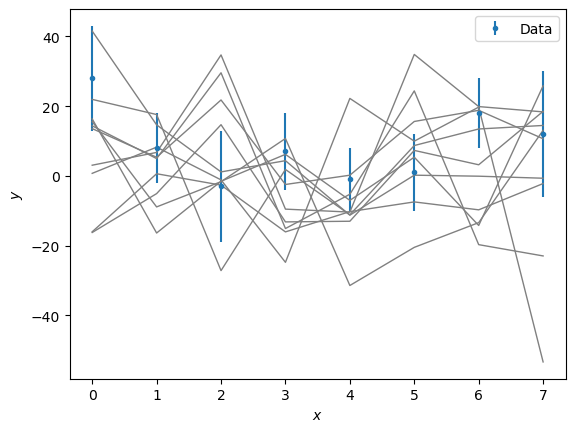

In [12]:
x_obs = np.arange(len(y))

fig, ax = plot_linear_data_set(x_obs, y, sigma)
ax.plot(x_obs, prior_predictive_samples.T, c="grey", lw=1)
# ax.plot([], [], c="grey", lw=1, label="Prior predictive samples")
ax.legend();

In [13]:
samples = mcmc.get_samples()

In [14]:
rng_key, master_key = jax.random.split(master_key)

posterior_predictive = numpyro.infer.Predictive(model=eight_schools, posterior_samples=samples)
posterior_predictive_samples = posterior_predictive(rng_key=rng_key, J=8, sigma=sigma)["obs"]

model_predictive_samples = samples["mu"]

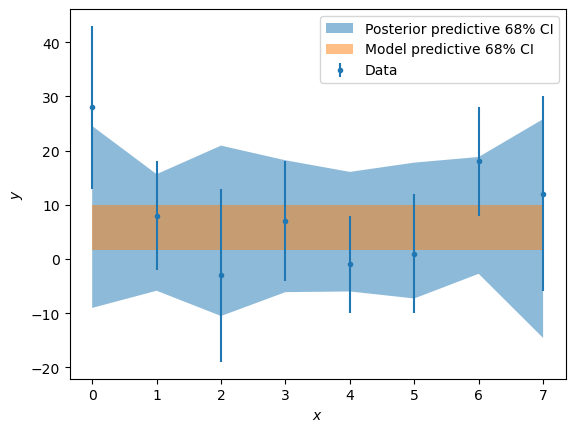

In [15]:
fig, ax = plot_linear_data_set(x_obs, y, sigma)

ax.fill_between(x_obs, *np.quantile(posterior_predictive_samples, [0.16, 0.84], axis=0), alpha=0.5, label="Posterior predictive 68% CI")
ax.fill_between(x_obs, *np.quantile(model_predictive_samples, [0.16, 0.84], axis=0), alpha=0.5, label="Model predictive 68% CI")
ax.legend();